# Превращение данных в датасет. <br>Dataset и DataLoader

**Что это такое?**
В PyTorch есть два ключевых класса для работы с данными:
- **`Dataset`** — хранилище ваших данных. Отвечает на вопросы: "Сколько у нас <br>образцов?" и "Дай мне образец по номеру N".
- **`DataLoader`** — "поставщик" данных для модели. Берёт образцы из Dataset, <br>собирает их в батчи, перемешивает и может параллельно загружать данные <br>с диска.

**Зачем это нужно?**
Нейросеть обучается не на одном примере за раз, а на **батчах** <br>(пакетах) по 16, 32, 64... изображений. DataLoader делает всю рутину: сам режет <br>данные на батчи, сам перемешивает, сам грузит в память. Вам остаётся только <br>сказать: "Дай мне следующий батч".

In [22]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

print(f"Версия PyTorch: {torch.__version__}")

Версия PyTorch: 2.12.0+cpu


## 1. Dataset: интерфейс `__len__` и `__getitem__`

Любой Dataset в PyTorch — это класс, унаследованный от `torch.utils.data.Dataset`. <br>У него **всего два обязательных метода**:

- `__len__(self)` — возвращает количество образцов в датасете.
- `__getitem__(self, idx)` — возвращает образец по индексу `idx` (обычно это <br>пара `(данные, метка)`).

Давайте напишем самый простой Dataset — просто числа от 0 до 99.

In [2]:
class SimpleNumbersDataset(Dataset):
    """Простейший датасет: хранит числа от 0 до N-1."""

    def __init__(self, size=100):
        # В __init__ мы обычно формируем доп. информацию о данных
        self.data = list(range(size))

    def __len__(self):
        # Отвечаем на вопрос "сколько у нас образцов?"
        return len(self.data)

    def __getitem__(self, idx):
        # Отвечаем на вопрос "дай образец по индексу idx"
        # Возвращаем пару: (само число, его метка — например, чётное/нечётное)
        x = self.data[idx]
        y = x % 2  # 0 = чётное, 1 = нечётное
        return (torch.tensor(x, dtype=torch.float32),
                torch.tensor(y, dtype=torch.long))

# Создаём датасет
dataset = SimpleNumbersDataset(size=100)

print("✅ Датасет создан.")
print(f"Размер датасета: {len(dataset)}")
print(f"\nОбразец №0: {dataset[0]}")
print(f"Образец №5: {dataset[5]}")
print(f"Образец №99: {dataset[99]}")

print("\n💡 Dataset — это просто 'контейнер'. Он НЕ умеет делать батчи!")
print("   За создание батчей отвечает DataLoader.")

✅ Датасет создан.
Размер датасета: 100

Образец №0: (tensor(0.), tensor(0))
Образец №5: (tensor(5.), tensor(1))
Образец №99: (tensor(99.), tensor(1))

💡 Dataset — это просто 'контейнер'. Он НЕ умеет делать батчи!
   За создание батчей отвечает DataLoader.


## 2. DataLoader: создание батчей, shuffle и <br>num_workers

Теперь обернём наш Dataset в DataLoader. Он умеет:
- **`batch_size`** — размер батча (сколько образцов в одной "стопке").
- **`shuffle`** — перемешивать ли данные в начале каждой эпохи.
- **`num_workers`** — сколько процессов использовать для параллельной загрузки.

Посмотрим, как DataLoader превращает наш датасет из 100 чисел в батчи.

In [3]:
# Создаём DataLoader
dataloader = DataLoader(
    dataset=dataset,
    batch_size=8,        # по 8 образцов в батче
    shuffle=True,        # перемешиваем в начале каждой эпохи
    num_workers=0        # 0 = загрузка в основном процессе (для начала достаточно)
)

print(f"Размер датасета: {len(dataset)}")
print(f"Размер батча: {dataloader.batch_size}")
print(f"Количество батчей в эпохе: {len(dataloader)} (= 100 / 8 = 12.5 → 13 батчей)")

print("\n🔄 Проходим по DataLoader (одна эпоха):")
for batch_idx, (inp, target) in enumerate(dataloader):
    print(f"\nБатч {batch_idx}:")
    print(f"  inp shape:    {inp.shape}, значения: {inp.tolist()}")
    print(f"  target shape: {target.shape}, значения: {target.tolist()}")

    if batch_idx >= 2:  # покажем только первые 3 батча
        print("\n  ... (остальные батчи пропускаем)")
        break

Размер датасета: 100
Размер батча: 8
Количество батчей в эпохе: 13 (= 100 / 8 = 12.5 → 13 батчей)

🔄 Проходим по DataLoader (одна эпоха):

Батч 0:
  inp shape:    torch.Size([8]), значения: [4.0, 28.0, 97.0, 9.0, 79.0, 95.0, 1.0, 11.0]
  target shape: torch.Size([8]), значения: [0, 0, 1, 1, 1, 1, 1, 1]

Батч 1:
  inp shape:    torch.Size([8]), значения: [29.0, 58.0, 59.0, 96.0, 85.0, 48.0, 26.0, 43.0]
  target shape: torch.Size([8]), значения: [1, 0, 1, 0, 1, 0, 0, 1]

Батч 2:
  inp shape:    torch.Size([8]), значения: [19.0, 16.0, 66.0, 90.0, 52.0, 39.0, 21.0, 73.0]
  target shape: torch.Size([8]), значения: [1, 0, 0, 0, 0, 1, 1, 1]

  ... (остальные батчи пропускаем)


### 🔍 Что произошло?

DataLoader:
1. Вызвал `dataset[i]` для каждого индекса от 0 до 99.
2. Собрал результаты в батчи по 8 штук.
3. **Стек** тензоров в один большой тензор формы `(batch_size, ...)`.
4. Перемешал порядок (потому что `shuffle=True`)..

💡 Обратите внимание: последний батч может быть **меньше** `batch_size` (в нашем <br>случае 100 / 8 = 12 батчей по 8 + 1 батч на 4 образца).

## 3. Dataset для реальных данных: <br>изображения + метки
**Подготовка MNIST:** скачиваем и раскладываем по папкам

Теперь переходим к реальным данным — **MNIST** (рукописные цифры 0-9).

На практике данные почти всегда хранятся на диске в виде файлов. Самая <br>распространённая структура — это **папки по классам**:
```
mnist_folder/
  ├── train/
  │   ├── 0/
  │   │   ├── img_00000.png
  │   │   ├── img_00001.png
  │   │   └── ...
  │   ├── 1/
  │   ├── 2/
  │   └── ...
  └── test/
      ├── 0/
      ├── 1/
      └── ...
```

Давайте скачаем MNIST и сохраним его именно в такой структуре. Это стандартный <br>способ организации данных для задач классификации изображений.

In [5]:
import os
import tempfile
from PIL import Image
from torchvision import datasets

# Скачиваем MNIST через torchvision (он уже готов к использованию)
mnist_raw_train = datasets.MNIST(root='./data', train=True, download=True)
mnist_raw_test = datasets.MNIST(root='./data', train=False, download=True)

print(f"Train: {len(mnist_raw_train)} картинок")
print(f"Test:  {len(mnist_raw_test)} картинок")
print(f"\nФормат одного образца: {mnist_raw_train[0][0].__class__.__module__} размера {mnist_raw_train[0][0].size}")
print(f"Метка: {mnist_raw_train[0][1]}")

Train: 60000 картинок
Test:  10000 картинок

Формат одного образца: PIL.Image размера (28, 28)
Метка: 5


In [6]:
# Раскладываем MNIST по папкам train/<class>/ и test/<class>/
MNIST_ROOT = './mnist_folder'

def save_mnist_to_folders(mnist_dataset, split_name, root_dir):
    """Сохраняет MNIST в структуру папок: root_dir/split_name/<label>/img_XXXXX.png"""
    split_dir = os.path.join(root_dir, split_name)

    # Создаём папки для всех 10 классов
    for label in range(10):
        os.makedirs(os.path.join(split_dir, str(label)), exist_ok=True)

    # Сохраняем каждую картинку
    for idx, (image, label) in enumerate(mnist_dataset):
        path = os.path.join(split_dir, str(label), f"img_{idx:05d}.png")
        image.save(path)

    print(f"✅ {split_name}: сохранено {len(mnist_dataset)} картинок")

save_mnist_to_folders(mnist_raw_train, 'train', MNIST_ROOT)
save_mnist_to_folders(mnist_raw_test, 'test', MNIST_ROOT)

dir_info = {}
for i, (_, _, files) in  enumerate(os.walk(os.path.join(MNIST_ROOT, 'train'))):
    if i>0:
        dir_info.update({i-1: len(files)})

print(f"\n📁 Структура папок создана в {MNIST_ROOT}/")
print("   mnist_folder/")
print("     ├── train/")
print(f"     │   ├── 0/  ({dir_info[0]} картинки)")
print(f"     │   ├── 1/  ({dir_info[1]} картинки)")
print("     │   └── ...")
print("     └── test/")
print("         ├── 0/")
print("         └── ...")

✅ train: сохранено 60000 картинок
✅ test: сохранено 10000 картинок

📁 Структура папок создана в ./mnist_folder/
   mnist_folder/
     ├── train/
     │   ├── 0/  (5923 картинки)
     │   ├── 1/  (6742 картинки)
     │   └── ...
     └── test/
         ├── 0/
         └── ...


## 4. Кастомный Dataset: `MNISTDataset`

Теперь напишем свой класс `MNISTDataset`, который будет:
- Принимать путь к папке (например, `mnist_folder/train`).
- Автоматически находить все подпапки (это наши классы: 0, 1, ..., 9).
- В `__getitem__` загружать картинку с диска и возвращать `(image, label)`.

**Главный принцип:** в `__init__` храним **только пути** к файлам, а сами картинки <br>грузим по одной в `__getitem__`. Так мы экономим RAM — даже если у вас 100 000 <br>картинок, в памяти будут только их пути (несколько мегабайт), а не <br>сами изображения (гигабайты).

In [28]:
class MNISTDataset(Dataset):
    """Кастомный Dataset для MNIST, лежащего в папках вида <root>/<class>/img_XXXXX.png."""

    def __init__(self, root_dir, transform=None):
        """
        Args:
            root_dir (str): Путь к папке с данными (например, './mnist_folder/train').
            transform (callable, optional): Трансформации для картинок.
        """
        self.root_dir = root_dir
        self.transform = transform

        # Собираем список всех картинок и их меток
        self.image_paths = []  # список путей к файлам
        self.labels = []       # список меток (int)

        # Получаем отсортированный список подпапок (это наши классы)
        class_folders = sorted(os.listdir(root_dir))

        # Создаём маппинг: имя папки → числовая метка
        self.class_to_idx = {
            folder_name: idx for idx, folder_name in enumerate(class_folders)
        }
        # Создаём маппинг: числовая метка → имя папки
        self.idx_to_class = {
            idx: folder_name for folder_name, idx in self.class_to_idx.items()
        }

        # Проходим по всем папкам и собираем пути
        for folder_name in class_folders:
            folder_path = os.path.join(root_dir, folder_name)
            if not os.path.isdir(folder_path):
                continue

            label = self.class_to_idx[folder_name]

            for filename in os.listdir(folder_path):
                if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(folder_path, filename))
                    self.labels.append(label)

        print(
            f"📦 Датасет загружен: {len(self.image_paths)} картинок"
            f" из {len(class_folders)} классов"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 1. Читаем путь и метку
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # 2. Загружаем картинку с диска
        image = Image.open(img_path)

        # 3. Применяем трансформации (если есть)
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

print("✅ Класс MNISTDataset определён.")

✅ Класс MNISTDataset определён.


In [8]:
# Пробуем создать датасет без трансформаций — просто чтобы проверить, что всё работает
train_dir = os.path.join(MNIST_ROOT, 'train')
mnist_train_raw = MNISTDataset(root_dir=train_dir)

# Смотрим на первые 5 образцов
print("\n🔍 Первые 5 образцов:")
for i in range(5):
    image, label = mnist_train_raw[i]
    print(
        f"  [{i}] Метка: {label.item()}",
        f", размер изображения: {image.size}",
        f", тип изображения: {image.__class__.__module__}"
    )

print("\n💡 Маппинг классов:")
print(f"  {'class_x':<3} --> label")
print(f"  {'-'*7}     -----")
for class_name, label in mnist_train_raw.class_to_idx.items():
    print(f"  class_{class_name:<1} --> {label}")

📦 Датасет загружен: 60000 картинокиз 10 классов

🔍 Первые 5 образцов:
  [0] Метка: 0 , размер изображения: (28, 28) , тип изображения: PIL.PngImagePlugin
  [1] Метка: 0 , размер изображения: (28, 28) , тип изображения: PIL.PngImagePlugin
  [2] Метка: 0 , размер изображения: (28, 28) , тип изображения: PIL.PngImagePlugin
  [3] Метка: 0 , размер изображения: (28, 28) , тип изображения: PIL.PngImagePlugin
  [4] Метка: 0 , размер изображения: (28, 28) , тип изображения: PIL.PngImagePlugin

💡 Маппинг классов:
  class_x --> label
  -------     -----
  class_0 --> 0
  class_1 --> 1
  class_2 --> 2
  class_3 --> 3
  class_4 --> 4
  class_5 --> 5
  class_6 --> 6
  class_7 --> 7
  class_8 --> 8
  class_9 --> 9


## 5. Трансформации (transforms)

Трансформации — это "конвейер обработки" данных. Они решают две задачи:
1. **Подготовка данных**: превратить PIL.Image в тензор, нормализовать.
2. **Аугментация**: случайно "испортить" картинку при обучении (повороты, сдвиги), <br>чтобы модель стала устойчивее.

Обычно для **train** и **val/test** используют разные трансформации:
- **Train**: аугментации + `ToTensor` + `Normalize` (чтобы модель училась на <br>"разных" картинках).
- **Val/Test**: только `ToTensor` + `Normalize` (нужна честная оценка качества, <br>без случайностей).

Для MNIST классические аугментации — это **случайный поворот** (±15°) и **случайный сдвиг** <br>(±2 пикселя), потому что цифры не должны быть перевёрнуты или зеркально отражены.

In [15]:
from torchvision.transforms import v2

# ==========================================
# Трансформации для обучения (с аугментациями)
# ==========================================
train_transform = v2.Compose([
    v2.ToImage(),                                    # PIL.Image → Image Tensor
    v2.ToDtype(torch.uint8, scale=True),             # [0, 255] → uint8 (опционально)

    # --- Аугментации (работают с Image тензором) ---
    v2.RandomRotation(degrees=15),                   # случайный поворот на ±15°
    v2.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)                         # случайный сдвиг на ±10%
    ),

    # --- Финальная конвертация ---
    v2.ToDtype(torch.float32, scale=True),           # uint8 → float32, [0,255] → [0,1]
    v2.Normalize(mean=(0.1307,), std=(0.3081,)),     # нормализация для MNIST
])

# ==========================================
# Трансформации для валидации и теста (БЕЗ аугментаций)
# ==========================================
val_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.1307,), std=(0.3081,)),
])

print("✅ Трансформации созданы.")
print("\n💡 transforms.Compose — это 'конвейер': трансформации применяются поочереди.")
print("   Последняя обычно Normalize.")
print("\n📋 train_transform:")
for t in train_transform.transforms:
    print(f"   • {t}")
print("\n📋 val_transform:")
for t in val_transform.transforms:
    print(f"   • {t}")

✅ Трансформации созданы.

💡 transforms.Compose — это 'конвейер': трансформации применяются поочереди.
   Последняя обычно Normalize.

📋 train_transform:
   • ToImage()
   • ToDtype(scale=True)
   • RandomRotation(degrees=[-15.0, 15.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0)
   • RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), interpolation=InterpolationMode.NEAREST, fill=0)
   • ToDtype(scale=True)
   • Normalize(mean=[0.1307], std=[0.3081], inplace=False)

📋 val_transform:
   • ToImage()
   • ToDtype(scale=True)
   • Normalize(mean=[0.1307], std=[0.3081], inplace=False)


### Стандартный способ сознания преобразований - это <br>упаковать всё в словарь.
Это делает код чище и удобнее, особенно когда у вас несколько сплитов <br>данных (train/val/test).

In [17]:
data_transforms = {
    'train': train_transform,
    'val': val_transform
}

Исходная картинка: метка = 0, размер = (28, 28)


C:\Users\Sergey\AppData\Local\Temp\ipykernel_5844\2976143102.py:28: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Sergey\Courses\PyTorch_2\my_project\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


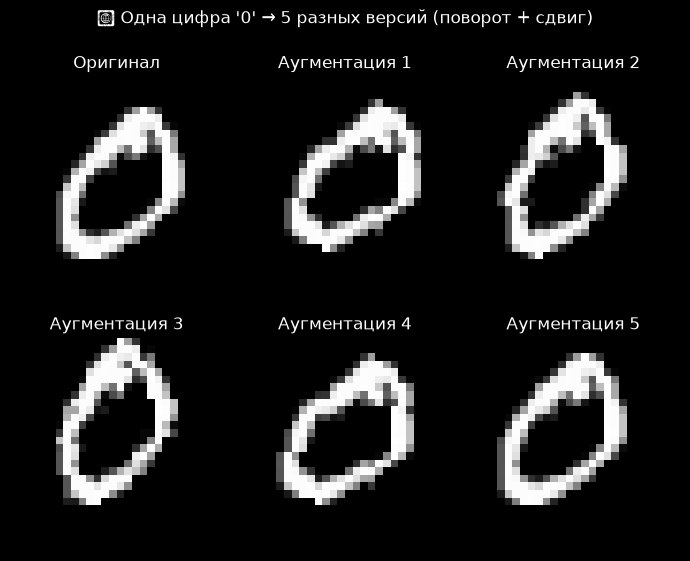

In [23]:
# Визуализируем, как одна и та же картинка выглядит после train_transform
# Берём первую картинку из датасета (без трансформаций)
sample_img, sample_label = mnist_train_raw[0]
print(f"Исходная картинка: метка = {sample_label}, размер = {sample_img.size}")

fig, axes = plt.subplots(2, 3, figsize=(7, 6))

# Оригинал
axes[0, 0].imshow(sample_img, cmap='gray')
axes[0, 0].set_title("Оригинал")
axes[0, 0].axis('off')

# Применяем train_transform 4 раза — каждый раз получим немного разную картинку!
for i in range(5):
    augmented = data_transforms['train'](sample_img)
    # Для визуализации нужно денормализовать обратно: x_orig = x_norm * std + mean
    augmented_vis = augmented * 0.3081 + 0.1307
    augmented_vis = augmented_vis.clamp(0, 1)

    # Убираем лишнюю размерность канала (1, 28, 28) → (28, 28)
    ax = axes.flat[i + 1]
    ax.imshow(augmented_vis.squeeze(), cmap='gray')
    ax.set_title(f"Аугментация {i+1}")
    ax.axis('off')

plt.suptitle(f"💡 Одна цифра '{sample_label}' → 5 разных версий (поворот + сдвиг)",
             fontsize=12)
plt.tight_layout()
plt.show()

## 6. Собираем всё вместе: <br>MNISTDataset + DataLoader

Теперь создадим два датасета (train и test) с **разными** трансформациями <br>и обернём их в DataLoader.

In [29]:
train_dir = os.path.join(MNIST_ROOT, 'train')
test_dir = os.path.join(MNIST_ROOT, 'test')

# Создаём датасеты с РАЗНЫМИ трансформациями
train_dataset = MNISTDataset(
    root_dir=train_dir,
    transform=data_transforms['train']   # ✅ с аугментациями
)

test_dataset = MNISTDataset(
    root_dir=test_dir,
    transform=data_transforms['val']    # ❌ без аугментаций
)

# Создаём DataLoader'ы
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,       # ✅ для train — ОБЯЗАТЕЛЬНО перемешиваем
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,      # ❌ для val перемешивание НЕ нужно
    num_workers=0
)

print(f"\nTrain батчей в эпохе: {len(train_loader)}")
print(f"Test батчей в эпохе:  {len(test_loader)}")

📦 Датасет загружен: 60000 картинок из 10 классов
📦 Датасет загружен: 10000 картинок из 10 классов

Train батчей в эпохе: 938
Test батчей в эпохе:  157


In [30]:
# Пройдёмся по одному батчу из train_loader
images, labels = next(iter(train_loader))

img_shape = images.shape
batch_size, channels, height, width = img_shape

print(f"Форма батча изображений: {images.shape}")
print(
    f"→ (batch_size={batch_size}, channels={channels}, "
    f"height={height}, width={width})"
)

Форма батча изображений: torch.Size([64, 1, 28, 28])
→ (batch_size=64, channels=1, height=28, width=28)


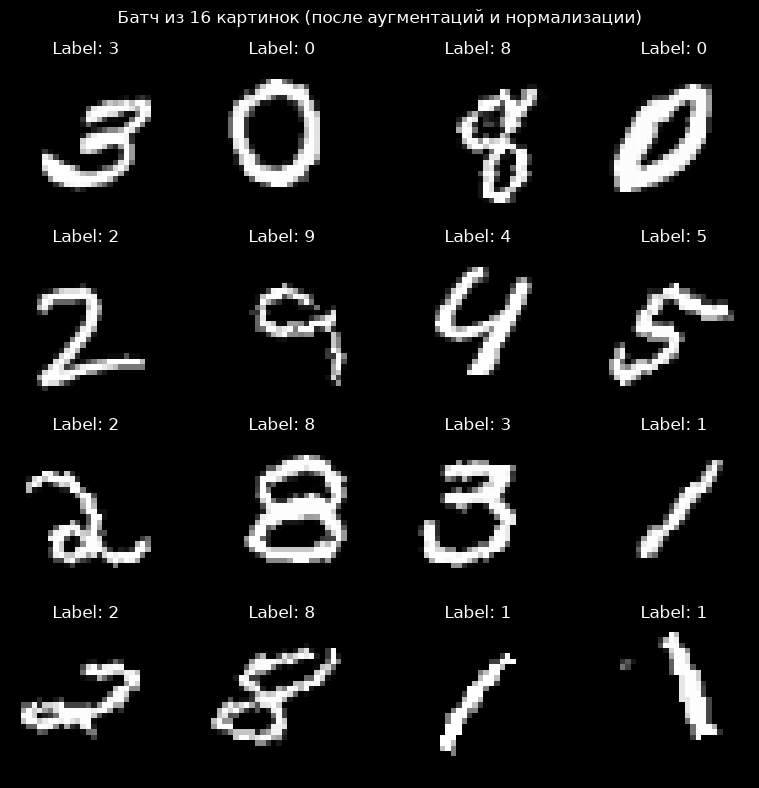

In [31]:
# Визуализируем батч (первые 16 картинок)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    # Денормализуем для визуализации
    img = images[i] * 0.3081 + 0.1307
    img = img.clamp(0, 1)

    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')

plt.suptitle("Батч из 16 картинок (после аугментаций и нормализации)", fontsize=12)
plt.tight_layout()
plt.show()

### 📊 Посчитаем распределение классов


In [32]:
# Распределение классов во всём train_loader
all_labels = []
for _, batch_labels in train_loader:
    all_labels.extend(batch_labels.tolist())

print(f"\n📊 Распределение классов во всём train датасете:")
for cls in range(10):
    count = all_labels.count(cls)
    print(f"  Класс {cls}: {count:5d} картинок ({100*count/len(all_labels):.1f}%)")


📊 Распределение классов во всём train датасете:
  Класс 0:  5923 картинок (9.9%)
  Класс 1:  6742 картинок (11.2%)
  Класс 2:  5958 картинок (9.9%)
  Класс 3:  6131 картинок (10.2%)
  Класс 4:  5842 картинок (9.7%)
  Класс 5:  5421 картинок (9.0%)
  Класс 6:  5918 картинок (9.9%)
  Класс 7:  6265 картинок (10.4%)
  Класс 8:  5851 картинок (9.8%)
  Класс 9:  5949 картинок (9.9%)


## 7. Встроенные датасеты `torchvision.datasets`

В предыдущих разделах мы написали свой `MNISTDataset` с нуля — это полезно, <br>чтобы понять, как всё устроено "под капотом".

Но на практике для популярных датасетов (MNIST, CIFAR-10, ImageNet, COCO и др.) <br>**не нужно писать свой Dataset** — он уже есть в `torchvision.datasets`. Эти классы <br>делают то же самое, что и наш `MNISTDataset`, но ещё умеют:
- автоматически скачивать данные,
- работать с разными форматами хранения.

Давайте сравним наш кастомный Dataset со встроенным:

In [34]:
# Встроенный MNIST из torchvision
mnist_builtin_train = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=data_transforms['train']
)

mnist_builtin_test = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=data_transforms['val']
)

print(f"MNIST Train (builtin): {len(mnist_builtin_train)} картинок")
print(f"MNIST Test  (builtin): {len(mnist_builtin_test)} картинок")

# Посмотрим на один образец
img, label = mnist_builtin_train[0]
print(f"\nФорма картинки: {img.shape}")  # (1, 28, 28) — 1 канал (ч/б), 28x28 пикселей
print(f"Метка: {label}")

print("\n💡 Встроенный датасет уже умеет всё, что и наш MNISTDataset,")
print("   плюс скачивание и проверку целостности данных.")

MNIST Train (builtin): 60000 картинок
MNIST Test  (builtin): 10000 картинок

Форма картинки: torch.Size([1, 28, 28])
Метка: 5

💡 Встроенный датасет уже умеет всё, что и наш MNISTDataset,
   плюс скачивание и проверку целостности данных.


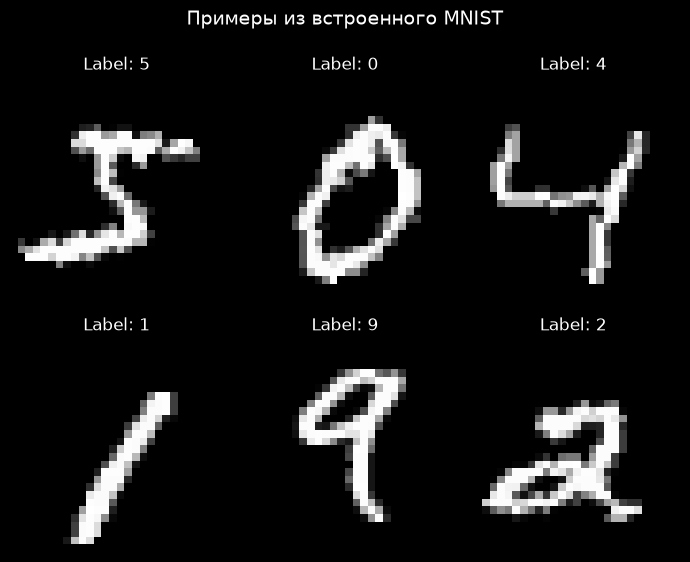

In [35]:
# Визуализируем несколько цифр из встроенного MNIST
fig, axes = plt.subplots(2, 3, figsize=(7, 6))
for i, ax in enumerate(axes.flatten()):
    img, label = mnist_builtin_train[i]
    # Денормализуем для визуализации
    img_vis = img * 0.3081 + 0.1307
    ax.imshow(img_vis.squeeze(), cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')

plt.suptitle("Примеры из встроенного MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [36]:
from torch.utils.data import random_split


train_dataset, val_dataset = random_split(mnist_builtin_train, [0.7, 0.3])

print(f"MNIST train: ----- {len(train_dataset)} картинок")
print(f"MNIST val: ------- {len(val_dataset)} картинок")
print(f"MNIST train + val: {len(train_dataset) + len(val_dataset)} картинок")

print(f"\nПреобразование в train_dataset:")
print(train_dataset.dataset.transform)
print(f"\nПреобразование в val_dataset:")
print(val_dataset.dataset.transform)

MNIST train: ----- 42000 картинок
MNIST val: ------- 18000 картинок
MNIST train + val: 60000 картинок

Преобразование в train_dataset:
Compose(
      ToImage()
      ToDtype(scale=True)
      RandomRotation(degrees=[-15.0, 15.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0)
      RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), interpolation=InterpolationMode.NEAREST, fill=0)
      ToDtype(scale=True)
      Normalize(mean=[0.1307], std=[0.3081], inplace=False)
)

Преобразование в val_dataset:
Compose(
      ToImage()
      ToDtype(scale=True)
      RandomRotation(degrees=[-15.0, 15.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0)
      RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), interpolation=InterpolationMode.NEAREST, fill=0)
      ToDtype(scale=True)
      Normalize(mean=[0.1307], std=[0.3081], inplace=False)
)


In [37]:
class MNISTWithTransform(Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform
    
    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label
    
    def __len__(self):
        return len(self.dataset)

# Встроенный MNIST из torchvision
mnist_builtin_train = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=None
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=data_transforms['val']
)

# Разбивием данные на train и val
train_data, val_data = random_split(mnist_builtin_train, [0.7, 0.3])

train_dataset = MNISTWithTransform(train_data, transform=data_transforms['train'])
val_dataset = MNISTWithTransform(val_data, transform=data_transforms['val'])

print(f"MNIST Train: {len(train_dataset)} картинок")
print(f"MNIST Val:   {len(val_dataset)} картинок")
print(f"MNIST Test:  {len(test_dataset)} картинок")

print(f"\nПреобразование в train_dataset:")
print(train_dataset.transform)
print(f"\nПреобразование в val_dataset:")
print(val_dataset.transform)
print(f"\nПреобразование в test_dataset:")
print(test_dataset.transform)

MNIST Train: 42000 картинок
MNIST Val:   18000 картинок
MNIST Test:  10000 картинок

Преобразование в train_dataset:
Compose(
      ToImage()
      ToDtype(scale=True)
      RandomRotation(degrees=[-15.0, 15.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0)
      RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), interpolation=InterpolationMode.NEAREST, fill=0)
      ToDtype(scale=True)
      Normalize(mean=[0.1307], std=[0.3081], inplace=False)
)

Преобразование в val_dataset:
Compose(
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.1307], std=[0.3081], inplace=False)
)

Преобразование в test_dataset:
Compose(
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.1307], std=[0.3081], inplace=False)
)


In [39]:
from torch.utils.data import Subset


# Быстрая проверка кода на 10 картинках
debug_dataset = Subset(train_dataset, list(range(10)))
debug_loader = DataLoader(debug_dataset, batch_size=10)

print('Dataset, из которого фармируется debug_dataset')
print(f"MNIST Train: {len(debug_dataset.dataset)} картинок")
print(f"\nMNIST debug_dataset: {len(debug_dataset)} картинок")


Dataset, из которого фармируется debug_dataset
MNIST Train: 42000 картинок

MNIST debug_dataset: 10 картинок


#### Когда вы создаете `Subset`, вы передаете ему два аргумента:
1. Исходный датасет.
2. Список индексов.

#### Используйте `Subset`, когда вам нужно:
- Взять часть большого датасета, не копируя его.
- Применить к одной и той же "сырой" выборке разные наборы трансформаций.
- Быстро протестировать код на маленьком куске данных.

## 8. 🚨 Подводные камни

### Камень №1: `num_workers` больше нуля.

- На Windows `num_workers > 0` может вызывать странные ошибки или <br>зависания. Решение:
  - Для начала ставьте `num_workers=0`.
  - Если нужна скорость — попробуйте `num_workers=2` и добавьте:
    ```python
    if __name__ == '__main__':
        # вызов функций здесь
    ```
- На Linux/Mac `num_workers=4` обычно работает без проблем.
- Увеличение значения `num_workers`, не всегда ускаряет обучение. Как правило <br>4-8 достаточно.
- Желательно не выставлять `num_workers` больше, чем физических ядер процессора.


### Камень №2: `collate_fn` для нестандартных данных

По умолчанию DataLoader "склеивает" образцы в тензор через `torch.stack`. Но что <br>если у вас объекты разной длины (например, предложения разной длины в NLP)?

Тогда нужно передать свою функцию `collate_fn`.

In [66]:
# Пример: датасет с "предложениями" разной длины
class TextDataset(Dataset):
    def __init__(self):
        self.texts = [
            [1, 2, 3],           # длина 3
            [4, 5, 6, 7, 8],     # длина 5
            [9, 10],             # длина 2
            [11, 12, 13, 14],    # длина 4
        ]
        self.labels = [0, 1, 0, 1]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return torch.tensor(self.texts[idx]), self.labels[idx]

text_dataset = TextDataset()

# ❌ Обычный DataLoader упадёт — нельзя сделать stack из тензоров разной длины
print("❌ Без collate_fn:")
try:
    bad_loader = DataLoader(text_dataset, batch_size=2)
    next(iter(bad_loader))
except RuntimeError as e:
    print("Ошибка (как и ожидалось):", str(e)[:100] + "...\n")

# ✅ Решение: пишем свою collate_fn, которая делает padding
from torch.nn.utils.rnn import pad_sequence

def my_collate_fn(batch):
    # batch — это список кортежей [(text1, label1), (text2, label2), ...]
    texts = [item[0] for item in batch]
    labels = [item[1] for item in batch]

    # Дополняем все тексты до максимальной длины нулями
    texts_padded = pad_sequence(texts, batch_first=True, padding_value=0)
    labels_tensor = torch.tensor(labels)

    return texts_padded, labels_tensor

good_loader = DataLoader(
    text_dataset,
    batch_size=2,
    collate_fn=my_collate_fn  # ✅ передаём свою функцию склейки
)

batch_texts, batch_labels = next(iter(good_loader))
print("✅ С collate_fn всё работает:")
print(f"Тексты (с padding):\n{batch_texts}")
print(f"\nМетки: {batch_labels}")

❌ Без collate_fn:
Ошибка (как и ожидалось): stack expects each tensor to be equal size, but got [3] at entry 0 and [5] at entry 1...

✅ С collate_fn всё работает:
Тексты (с padding):
tensor([[1, 2, 3, 0, 0],
        [4, 5, 6, 7, 8]])

Метки: tensor([0, 1])


### Камень №3: `drop_last=True`

Если размер датасета не делится на `batch_size`, последний батч будет **меньше** <br>обычного. Для BatchNorm это может быть проблемой (он ожидает стабильный размер батча).

Решение: `drop_last=True` — отбросить последний маленький батч.

In [40]:
# Возьмём маленький кусочек train_dataset для наглядности (100 картинок)
small_dataset = torch.utils.data.Subset(train_dataset, range(100))

# batch_size=30 → 100/30 = 3 батча по 30 + 1 батч на 10 картинок
loader_normal = DataLoader(small_dataset, batch_size=30, shuffle=False)
loader_drop = DataLoader(small_dataset, batch_size=30, shuffle=False, drop_last=True)

print("Без drop_last:")
for i, (x, y) in enumerate(loader_normal):
    print(f"  Батч {i}: размер {x.shape[0]}")

print("\nС drop_last=True:")
for i, (x, y) in enumerate(loader_drop):
    print(f"  Батч {i}: размер {x.shape[0]}")

print("\n💡 drop_last=True особенно полезно для train с BatchNorm.")

Без drop_last:
  Батч 0: размер 30
  Батч 1: размер 30
  Батч 2: размер 30
  Батч 3: размер 10

С drop_last=True:
  Батч 0: размер 30
  Батч 1: размер 30
  Батч 2: размер 30

💡 drop_last=True особенно полезно для train с BatchNorm.


## 9. Структура папок и `ImageFolder`

Если у вас картинки разложены по папкам вида:
```
dataset/
  ├── cats/
  │   ├── cat_001.jpg
  │   └── cat_002.jpg
  └── dogs/
      ├── dog_001.jpg
      └── dog_002.jpg
```

то вам повезло — в `torchvision` есть готовый класс `ImageFolder`, который сам:
- обойдёт папки,
- назначит метки по именам подпапок (cats=0, dogs=1),
- создаст Dataset.

Это **самый частый сценарий** для задач классификации изображений. По сути, <br>`ImageFolder` делает то же самое, что и наш `MNISTDataset`, но в более <br>универсальной форме.

In [42]:
import os
import numpy as np
from PIL import Image

# Параметры
MY_DATASET_ROOT = "./my_dataset"
classes = {
    "cat": 5,
    "dog": 3,
    "next_class": 7
}
img_size = 32
channels = 3

# Создание структуры папок и генерация изображений
for class_name, num_images in classes.items():
    # Создаем папку класса
    class_dir = os.path.join(MY_DATASET_ROOT, class_name)
    os.makedirs(class_dir, exist_ok=True)
    
    # Генерируем изображения
    for i in range(num_images):
        # Создаем случайное изображение 32x32x3
        img_array = np.random.randint(
            0, 256,
            (img_size, img_size, channels),
            dtype=np.uint8
        )
        
        # Создаем PIL изображение и сохраняем
        img = Image.fromarray(img_array)
        img_path = os.path.join(class_dir, f"img_{i:02d}.png")
        img.save(img_path)

print("Готово! Структура датасета создана.")

Готово! Структура датасета создана.


In [43]:
from torchvision.datasets import ImageFolder

# ImageFolder работает с нашей структурой mnist_folder/train/
# (подпапки '0', '1', ..., '9' станут классами)
MY_DATASET_ROOT = "./my_dataset"

image_folder_dataset = ImageFolder(
    root=MY_DATASET_ROOT,
    transform=data_transforms['train']
)

print(f"Размер датасета: {len(image_folder_dataset)}")
print("\n💡 Маппинг классов:")
print(f"  {'class':<6} --> label")
print(f"  {'-'*7}   ------")
for class_name, label in image_folder_dataset.class_to_idx.items():
    print(f"  {class_name:<10} --> {label}")

# Проверяем
img, label = image_folder_dataset[0]
print(f"\nПервый образец: label={label} (класс '{image_folder_dataset.classes[label]}')")
print(f"Форма тензора: {img.shape}")

print("\n💡 ImageFolder — это 'ленивый' Dataset: он не грузит всё в память,")
print("   а хранит только пути. Картинки читаются в __getitem__.")
print("\n💡 Наш MNISTDataset — это, по сути, упрощённая версия ImageFolder,")
print("   написанная вручную для образовательных целей.")

Размер датасета: 15

💡 Маппинг классов:
  class  --> label
  -------   ------
  cat        --> 0
  dog        --> 1
  next_class --> 2

Первый образец: label=0 (класс 'cat')
Форма тензора: torch.Size([3, 32, 32])

💡 ImageFolder — это 'ленивый' Dataset: он не грузит всё в память,
   а хранит только пути. Картинки читаются в __getitem__.

💡 Наш MNISTDataset — это, по сути, упрощённая версия ImageFolder,
   написанная вручную для образовательных целей.


## Итоги видео:

1. **`Dataset`** — это класс с двумя обязательными методами:
   - `__len__()` — размер датасета.
   - `__getitem__(idx)` — один образец по индексу.

2. **`DataLoader`** оборачивает Dataset и умеет:
   - собирать батчи (`batch_size`),
   - перемешивать (`shuffle`),
   - параллельно грузить данные (`num_workers`),
   - отбрасывать последний маленький батч (`drop_last`).

3. **Трансформации** (`v2.Compose`) — конвейер обработки данных:
   - Для **train**:
        - `ToImage`
        - `ToDtype(torch.uint8, scale=True)`
        - аугментации
        - `ToDtype(torch.float32, scale=True)`
        - `Normalize`.
   - Для **val/test**:
        - `ToImage`
        - `ToDtype(torch.float32, scale=True)`
        - `Normalize`.

4. **Кастомный Dataset** — пишется за 10 минут. Главное — хранить в `__init__` **пути**, а данные грузить в `__getitem__`.

5. **`ImageFolder`** — готовый Dataset для классификации, если картинки разложены по папкам. Работает с любой структурой вида `<root>/<class_name>/<images>`.

6. **Подводные камни**:
   - `num_workers > 0` на Windows может глючить → начинайте с 0.
   - Для данных разной длины нужна своя `collate_fn`.
   - `shuffle=True` только для train, для val/test — `False`.
   - `drop_last=True` спасает, если у вас BatchNorm и размер датасета не делится на batch_size.


## 📚 Домашнее задание: Собираем свой первый датасет

В этом задании вы соберёте **реальный датасет с нуля** — сфотографируете два разных объекта, разложите их по папкам и загрузите через `ImageFolder`. Это именно то, чем вы будете заниматься в 90% реальных проектов!

### 📋 Шаг 1: Выберите два объекта

Выберите **две категории** объектов, которые вас окружают. Вот примеры для вдохновения:

| Категория А | Категория Б |
|-------------|-------------|
| 👟 Кроссовки | 👞 Туфли |
| 👕 Футболки | 🩳 Шорты |
| 🥄 Ложки | 🍴 Вилки |
| 🍎 Яблоки | 🍊 Апельсины |
| 📕 Красные книги | 🔵 Синие книги |
| ☕ Кружки | 🥤 Стаканы |

💡 **Совет:** Выбирайте объекты, которые легко найти дома, которые визуально отличаются друг от друга.

### 📸 Шаг 2: Сделайте фотографии (по 20-30 штук на каждый объект, можно больше)

Используйте камеру телефона. **Строго соблюдайте эти правила:**

✅ **Правила съёмки:**
1. **Один объект на кадре** — никаких "кроссовок рядом с туфлями"
2. **Крупный план** — объект должен занимать большую часть кадра
3. **Хорошая видимость** — по фото должно быть однозначно понятно, что это за объект
4. **Объект в фокусе** — никаких размытых снимков

🌟 **Для разнообразия (чем больше — тем лучше для модели!):**
- Разные **ракурсы** (сверху, сбоку, спереди)
- Разное **освещение** (дневной свет, лампа, тень)
- Разный **фон** (стол, пол, диван, улица)

### 📁 Шаг 3: Создайте структуру папок

Создайте папку с данными в формате, который понимает `ImageFolder`:
```
my_dataset/
├── class_A/ # например, sneakers/
│ ├── img_001.jpg
│ ├── img_002.jpg
│ └── ... (20-30 фото)
└── class_B/ # например, shoes/
├── img_001.jpg
├── img_002.jpg
└── ... (20-30 фото)
```


⚠️ **Важно:** Имена папок (`class_A`, `class_B`) станут именами классов — выбирайте понятные названия на английском.

### 💻 Шаг 4: Загрузите данные через ImageFolder

```python
import torch
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 1. Опишите трансформации
train_transform = v2.Compose([
    ...
])

val_transform = v2.Compose([
    ...
])

data_transforms = {
    'train': train_transform,
    'val': val_transform
}

# 2. Загрузите датасет
dataset = datasets.ImageFolder( ... )

# 3. Проверьте, что всё работает
print(f"Количество изображений: {len(dataset)}")
print(f"Классы: {dataset.classes}")
print(f"Маппинг классов: {dataset.class_to_idx}")

# 4. Посмотрите на один образец
img, label = dataset[0]
print(f"Форма тензора: {img.shape}")
print(f"Метка: {label} ({dataset.classes[label]})")
```

### 🎨 Шаг 5: Визуализируйте датасет

Постройте сетку из 10 случайных изображений и убедитесь, что классы не перепутаны:

```python
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flatten()):
    idx = torch.randint(len(dataset), (1,)).item()
    img, label = dataset[idx]
    # Денормализация для визуализации
    img_vis = img * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + \
              torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    img_vis = img_vis.clamp(0, 1).permute(1, 2, 0)
    ax.imshow(img_vis)
    ax.set_title(f"{dataset.classes[label]}")
    ax.axis('off')
plt.suptitle("Случайные изображения из моего датасета", fontsize=14)
plt.tight_layout()
plt.show()
```

### 📊 Шаг 6: Проверьте баланс классов

Распечатайте, сколько изображений в каждом классе. В идеале должно быть примерно поровну:

```python
TODO
```

### ⭐ Бонус (со звёздочкой):
1. Добавьте аугментации для train-части (RandomHorizontalFlip, RandomRotation, ColorJitter) и посмотрите, как меняется одна и та же картинка.
2. Напишите свой класс MyDataset(Dataset), он должен содержать методы __init__, __len__ и __getitem__.
3. Используя класс MyDataset(Dataset) пройдите все шаги с 4 по 6 включительно.

### 🎯 Что вы получите в результате:
- ✅ Реальный датасет из 40-60 фотографий
- ✅ Понимание структуры папок для ImageFolder
- ✅ Опыт работы с transforms и DataLoader
- ✅ Готовую основу для обучения нейросети на своих данных! 🚀

💬 Поделитесь в комментариях: какие два объекта вы выбрали и сколько фотографий получилось! Самые креативные пары (например, "носки с дырками" vs "целые носки") получат ❤️
